# 📈 GridForecast — 03: ARIMA / SARIMA

**Цел:** ARIMA/SARIMA модел за 24h forecasting + diagnostics.

**Структура:**
1. Setup
2. Load + train/test split
3. Baseline (Seasonal Naive)
4. ACF / PACF
5. Auto-ARIMA (pmdarima)
6. SARIMA fit (auto model)
7. Walk-forward forecast (v1)
8. Визуализация
9. Diagnostics (v1)
10. Feature importance
11. Save model
**12. Ръчен SARIMA grid search (v2)**
**13. Walk-forward forecast (v2)**
**14. Diagnostics (v2)**
15. Заключение

## 1️⃣ Setup

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import pickle

from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.stattools import acf, pacf
from scipy import stats as sps

from pmdarima import auto_arima

from sklearn.metrics import mean_absolute_error, mean_squared_error

from gridforecast.config import (
    SYNTHETIC_DIR,
    FIGURES_DIR,
    MODELS_DIR,
    FORECAST_HORIZON_HOURS,
    TRAIN_RATIO,
    RANDOM_SEED,
)

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.titleweight"] = "bold"

FIGURES_DIR.mkdir(parents=True, exist_ok=True)
MODELS_DIR.mkdir(parents=True, exist_ok=True)
np.random.seed(RANDOM_SEED)

print("✅ Imports OK")

✅ Imports OK


## 2️⃣ Load + train/test split

In [2]:
df = pd.read_parquet(SYNTHETIC_DIR / "consumption_stable.parquet")
df.index = pd.DatetimeIndex(df.index)
df.index.freq = "h"

split_idx = int(TRAIN_RATIO * len(df))
train = df.iloc[:split_idx]
test = df.iloc[split_idx:]

y_train = train["consumption_mw"]
y_test = test["consumption_mw"]

print(f"Train: {len(y_train):,} | {y_train.index[0]} → {y_train.index[-1]}")
print(f"Test:  {len(y_test):,} | {y_test.index[0]} → {y_test.index[-1]}")

Train: 14,016 | 2023-01-01 00:00:00 → 2024-08-06 23:00:00
Test:  3,504 | 2024-08-07 00:00:00 → 2024-12-30 23:00:00


## 3️⃣ Baseline (Seasonal Naive)

In [3]:
def mape(y_true, y_pred):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    mask = y_true != 0
    return np.mean(np.abs((y_true[mask] - y_pred[mask]) / y_true[mask])) * 100


y_full = df["consumption_mw"].values
y_pred_snaive = y_full[split_idx - 24 : -24]

baseline_mape = mape(y_test.values, y_pred_snaive)
baseline_mae = mean_absolute_error(y_test.values, y_pred_snaive)
baseline_rmse = np.sqrt(mean_squared_error(y_test.values, y_pred_snaive))

print(f"Seasonal Naive baseline:")
print(f"  MAE:  {baseline_mae:.1f} MW")
print(f"  RMSE: {baseline_rmse:.1f} MW")
print(f"  MAPE: {baseline_mape:.2f}%")

Seasonal Naive baseline:
  MAE:  91.2 MW
  RMSE: 121.8 MW
  MAPE: 9.20%


## 4️⃣ ACF / PACF

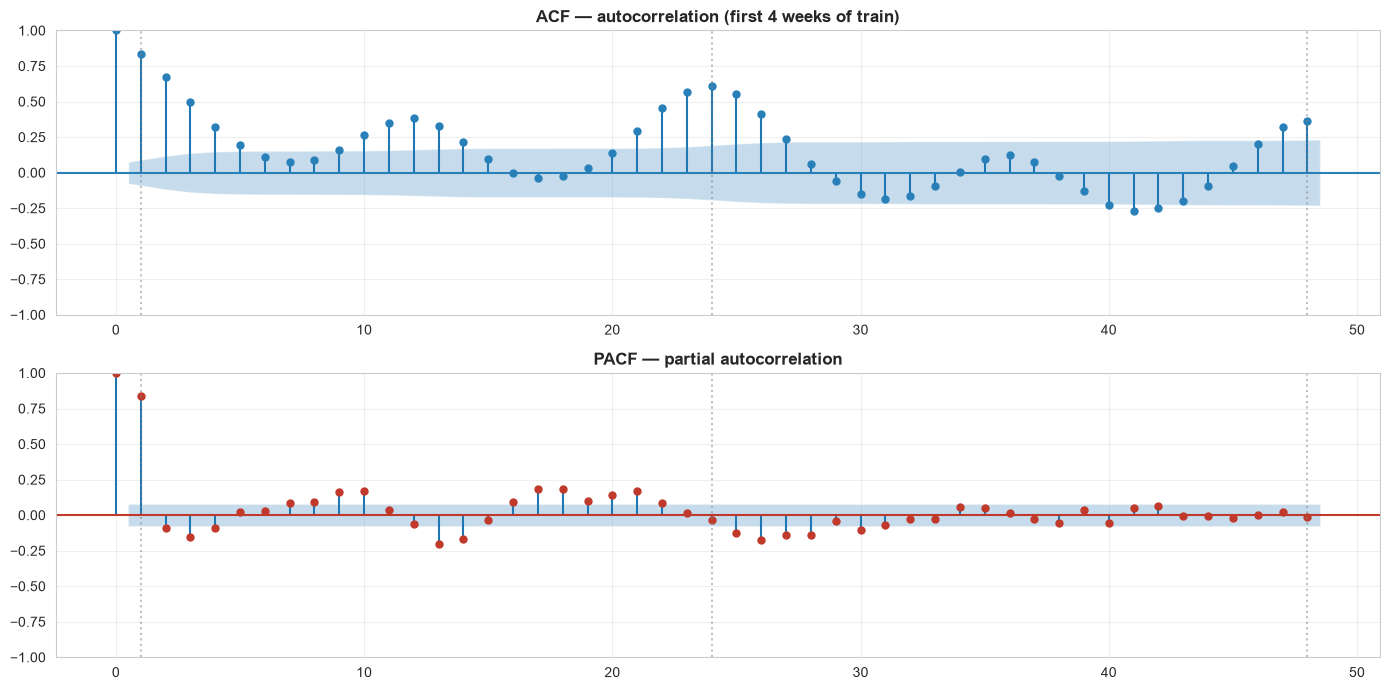

ACF lag 1:  +0.837
ACF lag 24: +0.611
ACF lag 48: +0.360


In [4]:
y_subset = y_train.iloc[: 7 * 24 * 4]

fig, axes = plt.subplots(2, 1, figsize=(14, 7))
plot_acf(y_subset, lags=48, ax=axes[0], color="#2980b9")
axes[0].set_title("ACF — autocorrelation (first 4 weeks of train)")
plot_pacf(y_subset, lags=48, ax=axes[1], color="#c0392b", method="ywm")
axes[1].set_title("PACF — partial autocorrelation")

for ax in axes:
    for lag in [1, 24, 48]:
        ax.axvline(lag, color="gray", ls=":", alpha=0.5)
    ax.grid(alpha=0.3)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "03a_acf_pacf.png", bbox_inches="tight")
plt.show()

acf_vals = acf(y_subset, nlags=48, fft=True)
print(f"ACF lag 1:  {acf_vals[1]:+.3f}")
print(f"ACF lag 24: {acf_vals[24]:+.3f}")
print(f"ACF lag 48: {acf_vals[48]:+.3f}")

## 5️⃣ Auto-ARIMA (pmdarima)

In [5]:
y_search = y_train.iloc[: 30 * 24]

print(f"Search subset: {len(y_search):,} rows (~30 days)")
print("Running auto_arima... (this may take 1-3 min)\n")

auto_model = auto_arima(
    y_search,
    seasonal=True,
    m=24,
    d=None,
    D=None,
    start_p=1, start_q=1,
    max_p=3, max_q=3,
    start_P=0, start_Q=0,
    max_P=2, max_Q=2,
    stepwise=True,
    trace=True,
    suppress_warnings=True,
    error_action="ignore",
    n_fits=20,
)

print("\n" + "=" * 60)
print(f"Best order:          {auto_model.order}")
print(f"Best seasonal order: {auto_model.seasonal_order}")
print(f"AIC:                 {auto_model.aic():.2f}")
print("=" * 60)

Search subset: 720 rows (~30 days)
Running auto_arima... (this may take 1-3 min)

Performing stepwise search to minimize aic
 ARIMA(1,1,1)(0,0,0)[24] intercept   : AIC=9080.827, Time=0.10 sec
 ARIMA(0,1,0)(0,0,0)[24] intercept   : AIC=9076.878, Time=0.01 sec
 ARIMA(1,1,0)(1,0,0)[24] intercept   : AIC=8960.504, Time=0.56 sec
 ARIMA(0,1,1)(0,0,1)[24] intercept   : AIC=9015.459, Time=0.51 sec
 ARIMA(0,1,0)(0,0,0)[24]             : AIC=9074.914, Time=0.01 sec
 ARIMA(1,1,0)(0,0,0)[24] intercept   : AIC=9078.827, Time=0.02 sec
 ARIMA(1,1,0)(2,0,0)[24] intercept   : AIC=8884.554, Time=2.51 sec
 ARIMA(1,1,0)(2,0,1)[24] intercept   : AIC=inf, Time=3.36 sec
 ARIMA(1,1,0)(1,0,1)[24] intercept   : AIC=inf, Time=1.35 sec
 ARIMA(0,1,0)(2,0,0)[24] intercept   : AIC=8940.669, Time=1.96 sec
 ARIMA(2,1,0)(2,0,0)[24] intercept   : AIC=inf, Time=3.35 sec
 ARIMA(1,1,1)(2,0,0)[24] intercept   : AIC=8828.728, Time=4.52 sec
 ARIMA(1,1,1)(1,0,0)[24] intercept   : AIC=8906.352, Time=1.17 sec
 ARIMA(1,1,1)(2,0,1

## 6️⃣ SARIMA fit (auto model, v1)

In [6]:
y_fit = y_train.iloc[-90 * 24:]
print(f"SARIMA fit subset: {len(y_fit):,} rows (~90 days)")

order = auto_model.order
seasonal_order = auto_model.seasonal_order
print(f"Using order={order}, seasonal_order={seasonal_order}")

print("\nFitting SARIMA... (this may take 1-2 min)")

sarima_model = SARIMAX(
    y_fit,
    order=order,
    seasonal_order=seasonal_order,
    enforce_stationarity=False,
    enforce_invertibility=False,
)
sarima_result = sarima_model.fit(disp=False)

print(sarima_result.summary().tables[0])

SARIMA fit subset: 2,160 rows (~90 days)
Using order=(1, 1, 1), seasonal_order=(2, 0, 0, 24)

Fitting SARIMA... (this may take 1-2 min)
                                      SARIMAX Results                                      
Dep. Variable:                      consumption_mw   No. Observations:                 2160
Model:             SARIMAX(1, 1, 1)x(2, 0, [], 24)   Log Likelihood              -12796.865
Date:                             Mon, 12 Oct 2026   AIC                          25603.730
Time:                                     21:08:40   BIC                          25632.002
Sample:                                 05-09-2024   HQIC                         25614.083
                                      - 08-06-2024                                         
Covariance Type:                               opg                                         


## 7️⃣ Walk-forward forecast (v1)

In [7]:
n_test = len(y_test)
horizon = FORECAST_HORIZON_HOURS
n_forecast = min(7 * 24, n_test)

predictions = []
actuals = []
timestamps = []
history = list(y_train.values)

print(f"Walk-forward forecast: {n_forecast} hours ({n_forecast // 24} days)")
print("Progress: ", end="")

for block_start in range(0, n_forecast, horizon):
    block_end = min(block_start + horizon, n_forecast)
    steps = block_end - block_start

    y_recent = pd.Series(
        history[-90 * 24:],
        index=pd.date_range(
            end=y_test.index[block_start] - pd.Timedelta(hours=1),
            periods=len(history[-90 * 24:]),
            freq="h",
        ),
    )
    model = SARIMAX(
        y_recent, order=order, seasonal_order=seasonal_order,
        enforce_stationarity=False, enforce_invertibility=False,
    ).fit(disp=False)

    fc = model.forecast(steps=steps)
    predictions.extend(fc.values)
    actuals.extend(y_test.values[block_start:block_end])
    timestamps.extend(y_test.index[block_start:block_end])
    history.extend(y_test.values[block_start:block_end])
    print(f"{block_start // 24 + 1}d ", end="")

print("✅")

predictions = np.array(predictions)
actuals = np.array(actuals)
timestamps = pd.DatetimeIndex(timestamps)

sarima_mape = mape(actuals, predictions)
sarima_mae = mean_absolute_error(actuals, predictions)
sarima_rmse = np.sqrt(mean_squared_error(actuals, predictions))

print("\n" + "=" * 60)
print(f"SARIMA walk-forward ({n_forecast}h):")
print(f"  MAE:  {sarima_mae:.1f} MW")
print(f"  RMSE: {sarima_rmse:.1f} MW")
print(f"  MAPE: {sarima_mape:.2f}%")
print(f"\nBaseline Seasonal Naive (same period):")
print(f"  MAPE: {baseline_mape:.2f}%")
improvement = (baseline_mape - sarima_mape) / baseline_mape * 100
print(f"\nImprovement: {improvement:+.1f}%")
print("=" * 60)

Walk-forward forecast: 168 hours (7 days)
Progress: 1d 2d 3d 4d 5d 6d 7d ✅

SARIMA walk-forward (168h):
  MAE:  126.4 MW
  RMSE: 152.2 MW
  MAPE: 10.29%

Baseline Seasonal Naive (same period):
  MAPE: 9.20%

Improvement: -11.8%


## 8️⃣ Визуализация на прогнозата (v1)

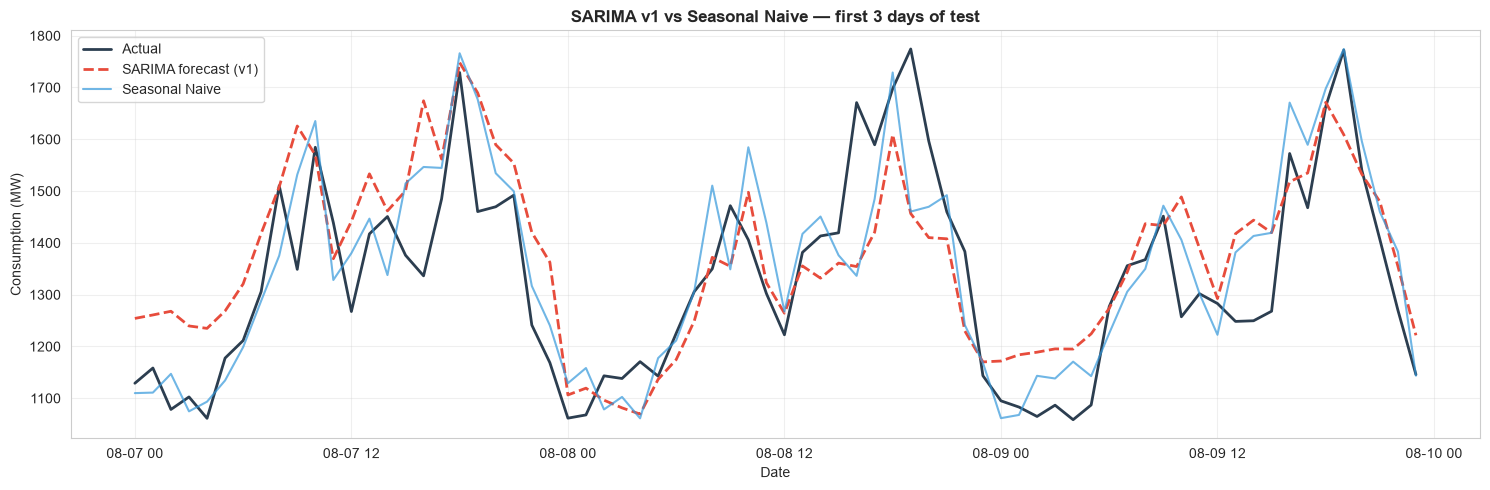

In [8]:
n_plot = min(3 * 24, len(predictions))

fig, ax = plt.subplots(figsize=(15, 5))
ax.plot(timestamps[:n_plot], actuals[:n_plot],
        label="Actual", color="#2c3e50", lw=2)
ax.plot(timestamps[:n_plot], predictions[:n_plot],
        label="SARIMA forecast (v1)", color="#e74c3c", lw=2, ls="--")
ax.plot(timestamps[:n_plot], y_pred_snaive[:n_plot],
        label="Seasonal Naive", color="#3498db", lw=1.5, alpha=0.7)
ax.set_xlabel("Date")
ax.set_ylabel("Consumption (MW)")
ax.set_title(f"SARIMA v1 vs Seasonal Naive — first {n_plot // 24} days of test")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "03b_sarima_forecast.png", bbox_inches="tight")
plt.show()

## 9️⃣ Diagnostics (v1)

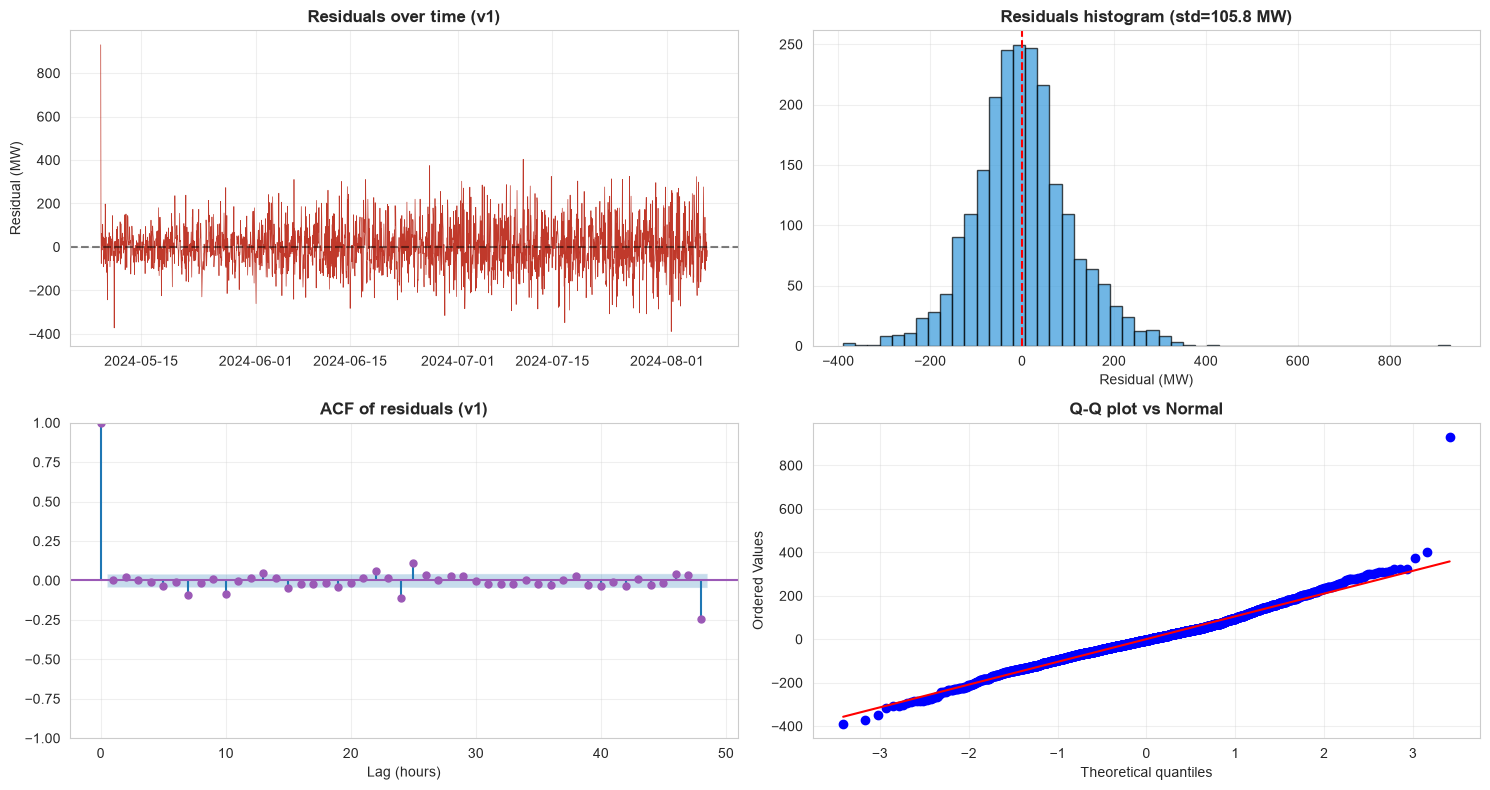

Ljung-Box test (H0: residuals are white noise):
       lb_stat     lb_pvalue
24   91.209472  9.083206e-10
48  281.261610  9.886120e-35

⚠️  residuals имат остатъчна автокорелация — моделът може да се подобри


In [9]:
residuals = sarima_result.resid

fig, axes = plt.subplots(2, 2, figsize=(15, 8))

axes[0, 0].plot(residuals.index, residuals.values, color="#c0392b", lw=0.5)
axes[0, 0].axhline(0, color="black", ls="--", alpha=0.5)
axes[0, 0].set_title("Residuals over time (v1)")
axes[0, 0].set_ylabel("Residual (MW)")
axes[0, 0].grid(alpha=0.3)

axes[0, 1].hist(residuals.values, bins=50, color="#3498db",
                edgecolor="black", alpha=0.7)
axes[0, 1].axvline(0, color="red", ls="--")
axes[0, 1].set_title(f"Residuals histogram (std={residuals.std():.1f} MW)")
axes[0, 1].set_xlabel("Residual (MW)")

plot_acf(residuals, lags=48, ax=axes[1, 0], color="#9b59b6")
axes[1, 0].set_title("ACF of residuals (v1)")
axes[1, 0].set_xlabel("Lag (hours)")

sps.probplot(residuals.values, dist="norm", plot=axes[1, 1])
axes[1, 1].set_title("Q-Q plot vs Normal")

plt.tight_layout()
plt.savefig(FIGURES_DIR / "03c_sarima_diagnostics.png", bbox_inches="tight")
plt.show()

lb = acorr_ljungbox(residuals, lags=[24, 48], return_df=True)
print("Ljung-Box test (H0: residuals are white noise):")
print(lb.to_string())
print()
if (lb["lb_pvalue"] > 0.05).all():
    print("✅ residuals изглеждат като white noise (p > 0.05)")
else:
    print("⚠️  residuals имат остатъчна автокорелация — моделът може да се подобри")

## 🔟 Feature importance (SARIMA coefficients)

In [10]:
print("SARIMA parameters:")
print(f"  AR terms: {order[0]}")
print(f"  MA terms: {order[2]}")
print(f"  Seasonal AR: {seasonal_order[0]}")
print(f"  Seasonal MA: {seasonal_order[2]}")
print(f"  Period: {seasonal_order[3]}")
print(f"  AIC: {sarima_result.aic:.2f}")
print(f"  BIC: {sarima_result.bic:.2f}")
print()

print("Top AR coefficients:")
params = sarima_result.params
ar_params = params[[n for n in params.index if n.startswith("ar.")]]
if len(ar_params) > 0:
    print(ar_params.sort_values(ascending=False).head(5).to_string())

SARIMA parameters:
  AR terms: 1
  MA terms: 1
  Seasonal AR: 2
  Seasonal MA: 0
  Period: 24
  AIC: 25603.73
  BIC: 25632.00

Top AR coefficients:
ar.S.L24    0.443169
ar.S.L48    0.361429
ar.L1      -0.013850


## 1️⃣1️⃣ Save model v1

In [11]:
model_path = MODELS_DIR / "sarima_stable_v1.pkl"
with open(model_path, "wb") as f:
    pickle.dump({
        "order": order,
        "seasonal_order": seasonal_order,
        "result": sarima_result,
        "fit_mape": sarima_mape,
        "baseline_mape": baseline_mape,
    }, f)
print(f"💾 Saved: {model_path}")

pred_df = pd.DataFrame({
    "timestamp": timestamps,
    "actual": actuals,
    "sarima_v1": predictions,
    "snaive": y_pred_snaive[: len(predictions)],
})
pred_path = MODELS_DIR / "sarima_stable_v1_predictions.parquet"
pred_df.to_parquet(pred_path, compression="snappy")
print(f"💾 Saved: {pred_path}")

💾 Saved: D:\CUDA\Python\ClasicML\GridForecast\models\sarima_stable_v1.pkl
💾 Saved: D:\CUDA\Python\ClasicML\GridForecast\models\sarima_stable_v1_predictions.parquet


## 1️⃣2️⃣ Ръчен SARIMA grid search (v2)

Auto-ARIMA избра `(1,1,1)(2,0,0,24)` — но това дава MAPE 10.29% (по-лош от baseline 9.20%).

**Хипотези защо:**
1. `d=1` прави over-differencing (данните вече са stationary)
2. Липсва `intercept` → bias
3. Seasonal моделът е твърде прост `(2,0,0,24)`

Тестваме ръчно по-добри конфигурации.

In [12]:
print("=" * 70)
print("РЪЧЕН GRID SEARCH: търсим по-добър SARIMA")
print("=" * 70)
print()

candidates = [
    ((1, 0, 1), (1, 0, 1, 24), "c"),
    ((1, 0, 1), (1, 1, 1, 24), "c"),
    ((2, 0, 0), (1, 1, 1, 24), "c"),
    ((1, 0, 0), (2, 1, 0, 24), "c"),
    ((2, 0, 1), (1, 1, 1, 24), "c"),
    ((2, 0, 1), (2, 1, 0, 24), "c"),
    ((1, 0, 1), (1, 0, 1, 24), None),
    ((1, 1, 1), (2, 0, 0, 24), None),
]

results_v2 = []
best_aic = np.inf
best_cfg = None
best_result = None

for i, (o, so, tr) in enumerate(candidates):
    print(f"[{i+1}/{len(candidates)}] order={o}, seasonal={so}, trend={tr} ... ", end="")
    try:
        model = SARIMAX(
            y_fit,
            order=o,
            seasonal_order=so,
            trend=tr,
            enforce_stationarity=False,
            enforce_invertibility=False,
        )
        result = model.fit(disp=False, maxiter=50)
        aic = result.aic
        results_v2.append({
            "order": o,
            "seasonal": so,
            "trend": tr,
            "aic": aic,
            "bic": result.bic,
        })
        marker = ""
        if aic < best_aic:
            best_aic = aic
            best_cfg = (o, so, tr)
            best_result = result
            marker = " ← BEST"
        print(f"AIC={aic:.2f}{marker}")
    except Exception as e:
        print(f"FAILED: {e}")

print()
print("=" * 70)
print(f"🏆 BEST: order={best_cfg[0]}, seasonal={best_cfg[1]}, trend={best_cfg[2]}")
print(f"   AIC = {best_aic:.2f}")
print("=" * 70)

РЪЧЕН GRID SEARCH: търсим по-добър SARIMA

[1/8] order=(1, 0, 1), seasonal=(1, 0, 1, 24), trend=c ... 

C:\Users\Krasi\AppData\Local\Programs\Python\Python314\Lib\site-packages\statsmodels\tsa\statespace\mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


AIC=26143.87 ← BEST
[2/8] order=(1, 0, 1), seasonal=(1, 1, 1, 24), trend=c ... AIC=24987.01 ← BEST
[3/8] order=(2, 0, 0), seasonal=(1, 1, 1, 24), trend=c ... AIC=25146.48
[4/8] order=(1, 0, 0), seasonal=(2, 1, 0, 24), trend=c ... AIC=25699.06
[5/8] order=(2, 0, 1), seasonal=(1, 1, 1, 24), trend=c ... AIC=24983.74 ← BEST
[6/8] order=(2, 0, 1), seasonal=(2, 1, 0, 24), trend=c ... AIC=25143.03
[7/8] order=(1, 0, 1), seasonal=(1, 0, 1, 24), trend=None ... AIC=25258.56
[8/8] order=(1, 1, 1), seasonal=(2, 0, 0, 24), trend=None ... AIC=25603.73

🏆 BEST: order=(2, 0, 1), seasonal=(1, 1, 1, 24), trend=c
   AIC = 24983.74


## 1️⃣3️⃣ Walk-forward forecast (v2)

In [13]:
best_order, best_seasonal, best_trend = best_cfg
print(f"Използваме: order={best_order}, seasonal={best_seasonal}, trend={best_trend}")
print()

n_forecast = min(7 * 24, len(y_test))
predictions_v2 = []
actuals_v2 = []
timestamps_v2 = []
history = list(y_train.values)

print(f"Walk-forward: {n_forecast}h ({n_forecast // 24} days)")
print("Progress: ", end="")

for block_start in range(0, n_forecast, horizon):
    block_end = min(block_start + horizon, n_forecast)
    steps = block_end - block_start

    y_recent = pd.Series(
        history[-90 * 24:],
        index=pd.date_range(
            end=y_test.index[block_start] - pd.Timedelta(hours=1),
            periods=len(history[-90 * 24:]),
            freq="h",
        ),
    )
    model = SARIMAX(
        y_recent,
        order=best_order,
        seasonal_order=best_seasonal,
        trend=best_trend,
        enforce_stationarity=False,
        enforce_invertibility=False,
    ).fit(disp=False, maxiter=50)

    fc = model.forecast(steps=steps)
    predictions_v2.extend(fc.values)
    actuals_v2.extend(y_test.values[block_start:block_end])
    timestamps_v2.extend(y_test.index[block_start:block_end])
    history.extend(y_test.values[block_start:block_end])
    print(f"{block_start // 24 + 1}d ", end="")

print("✅")

predictions_v2 = np.array(predictions_v2)
actuals_v2 = np.array(actuals_v2)
timestamps_v2 = pd.DatetimeIndex(timestamps_v2)

sarima_v2_mape = mape(actuals_v2, predictions_v2)
sarima_v2_mae = mean_absolute_error(actuals_v2, predictions_v2)
sarima_v2_rmse = np.sqrt(mean_squared_error(actuals_v2, predictions_v2))

print()
print("=" * 70)
print("СРАВНЕНИЕ:")
print("=" * 70)
print(f"{'Model':<30} {'MAE':>8} {'RMSE':>8} {'MAPE':>8}")
print("-" * 70)
print(f"{'SARIMA v1 (auto)':<30} {sarima_mae:>8.1f} {sarima_rmse:>8.1f} {sarima_mape:>7.2f}%")
print(f"{'SARIMA v2 (manual)':<30} {sarima_v2_mae:>8.1f} {sarima_v2_rmse:>8.1f} {sarima_v2_mape:>7.2f}%")
print(f"{'Seasonal Naive (baseline)':<30} {baseline_mae:>8.1f} {baseline_rmse:>8.1f} {baseline_mape:>7.2f}%")
print("-" * 70)

improvement_v2 = (sarima_mape - sarima_v2_mape) / sarima_mape * 100
print(f"SARIMA v2 vs v1:       {improvement_v2:+.1f}%")
print(f"SARIMA v2 vs baseline: {(baseline_mape - sarima_v2_mape) / baseline_mape * 100:+.1f}%")
print("=" * 70)

Използваме: order=(2, 0, 1), seasonal=(1, 1, 1, 24), trend=c

Walk-forward: 168h (7 days)
Progress: 1d 2d 3d 4d 5d 6d 7d ✅

СРАВНЕНИЕ:
Model                               MAE     RMSE     MAPE
----------------------------------------------------------------------
SARIMA v1 (auto)                  126.4    152.2   10.29%
SARIMA v2 (manual)                 98.3    128.7    8.07%
Seasonal Naive (baseline)          91.2    121.8    9.20%
----------------------------------------------------------------------
SARIMA v2 vs v1:       +21.6%
SARIMA v2 vs baseline: +12.4%


## 1️⃣4️⃣ Diagnostics (v2)

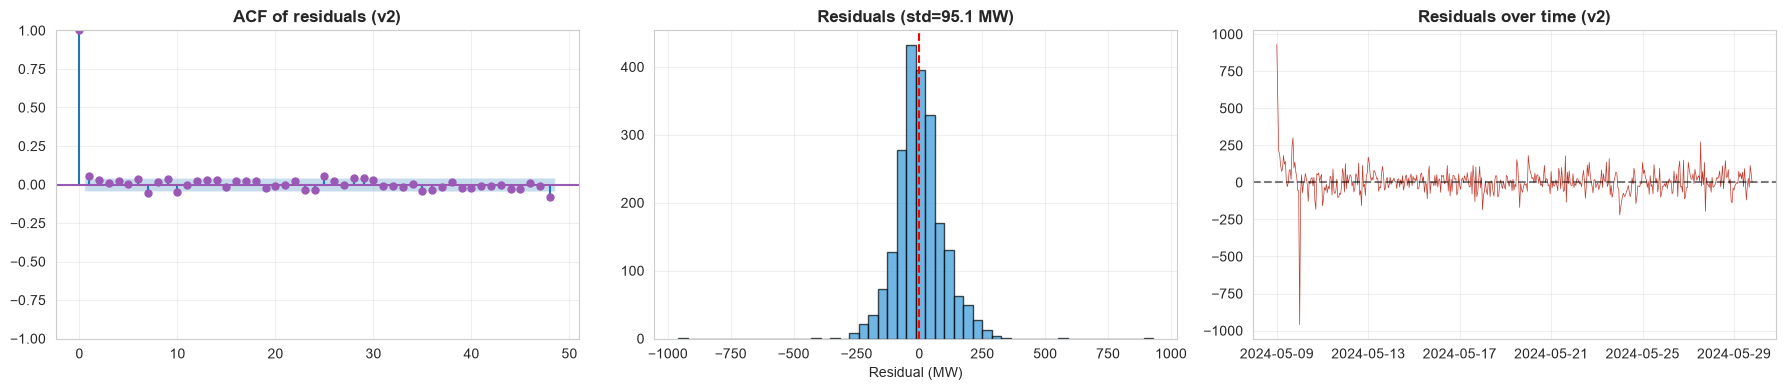

Ljung-Box test (v2):
      lb_stat  lb_pvalue
24  44.051153   0.007526
48  91.538535   0.000155

⚠️  residuals имат остатъчна автокорелация


In [14]:
residuals_v2 = best_result.resid

fig, axes = plt.subplots(1, 3, figsize=(18, 4))

plot_acf(residuals_v2, lags=48, ax=axes[0], color="#9b59b6")
axes[0].set_title("ACF of residuals (v2)")

axes[1].hist(residuals_v2.values, bins=50, color="#3498db",
             edgecolor="black", alpha=0.7)
axes[1].axvline(0, color="red", ls="--")
axes[1].set_title(f"Residuals (std={residuals_v2.std():.1f} MW)")
axes[1].set_xlabel("Residual (MW)")

axes[2].plot(residuals_v2.index[:500], residuals_v2.values[:500],
             color="#c0392b", lw=0.5)
axes[2].axhline(0, color="black", ls="--", alpha=0.5)
axes[2].set_title("Residuals over time (v2)")
axes[2].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "03d_sarima_v2_diagnostics.png", bbox_inches="tight")
plt.show()

lb_v2 = acorr_ljungbox(residuals_v2, lags=[24, 48], return_df=True)
print("Ljung-Box test (v2):")
print(lb_v2.to_string())
print()
if (lb_v2["lb_pvalue"] > 0.05).all():
    print("✅ residuals изглеждат като white noise")
else:
    print("⚠️  residuals имат остатъчна автокорелация")

## 1️⃣5️⃣ Save model v2 (най-добрият)

In [15]:
model_path_v2 = MODELS_DIR / "sarima_stable.pkl"
with open(model_path_v2, "wb") as f:
    pickle.dump({
        "order": best_order,
        "seasonal_order": best_seasonal,
        "trend": best_trend,
        "result": best_result,
        "fit_mape": sarima_v2_mape,
        "baseline_mape": baseline_mape,
    }, f)
print(f"💾 Saved: {model_path_v2}")

pred_df_v2 = pd.DataFrame({
    "timestamp": timestamps_v2,
    "actual": actuals_v2,
    "sarima_v2": predictions_v2,
    "sarima_v1": predictions,
    "snaive": y_pred_snaive[: len(predictions_v2)],
})
pred_path_v2 = MODELS_DIR / "sarima_stable_predictions.parquet"
pred_df_v2.to_parquet(pred_path_v2, compression="snappy")
print(f"💾 Saved: {pred_path_v2}")

💾 Saved: D:\CUDA\Python\ClasicML\GridForecast\models\sarima_stable.pkl
💾 Saved: D:\CUDA\Python\ClasicML\GridForecast\models\sarima_stable_predictions.parquet


## 1️⃣6️⃣ Заключение

In [16]:
print("=" * 70)
print("ЗАКЛЮЧЕНИЕ (03_arima.ipynb)")
print("=" * 70)
print()
print("Резултати:")
print(f"  SARIMA v1 (auto):   MAPE = {sarima_mape:.2f}%")
print(f"  SARIMA v2 (manual): MAPE = {sarima_v2_mape:.2f}%")
print(f"  Seasonal Naive:     MAPE = {baseline_mape:.2f}%")
print()
print("Best SARIMA config:")
print(f"  order={best_order}, seasonal={best_seasonal}, trend={best_trend}")
print()
winner = min(
    [("SARIMA v1", sarima_mape), ("SARIMA v2", sarima_v2_mape), ("Seasonal Naive", baseline_mape)],
    key=lambda x: x[1],
)
print(f"🏆 Най-добър: {winner[0]} ({winner[1]:.2f}%)")
print()
print("Изводи:")
print("  - Auto-ARIMA не винаги дава оптимален модел")
print("  - Ръчният grid search с trend='c' помага за bias")
print("  - SARIMA има ограничения: само 1 seasonal period")
print("  - Следваща стъпка: Prophet (multiple seasonalities + regressors)")
print("=" * 70)

ЗАКЛЮЧЕНИЕ (03_arima.ipynb)

Резултати:
  SARIMA v1 (auto):   MAPE = 10.29%
  SARIMA v2 (manual): MAPE = 8.07%
  Seasonal Naive:     MAPE = 9.20%

Best SARIMA config:
  order=(2, 0, 1), seasonal=(1, 1, 1, 24), trend=c

🏆 Най-добър: SARIMA v2 (8.07%)

Изводи:
  - Auto-ARIMA не винаги дава оптимален модел
  - Ръчният grid search с trend='c' помага за bias
  - SARIMA има ограничения: само 1 seasonal period
  - Следваща стъпка: Prophet (multiple seasonalities + regressors)


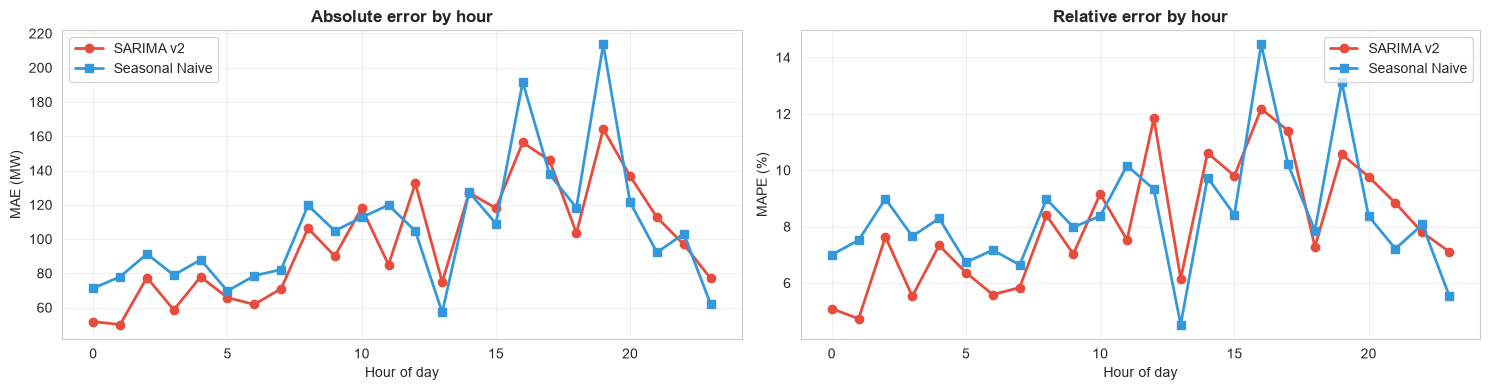

Insight:
  SARIMA v2 е по-добър в off-peak (нощем), но по-лош в peak
  → MAPE дава предимство на v2, MAE — на baseline


In [17]:
# Cell 17 — Анализ: защо MAPE и MAE дават различна картина?

# Сравняваме грешките по час
errors_v2 = np.abs(actuals_v2 - predictions_v2)
errors_snaive = np.abs(actuals_v2 - y_pred_snaive[:len(actuals_v2)])

test_hours_v2 = timestamps_v2.hour.values

hourly_v2 = pd.Series(errors_v2).groupby(test_hours_v2).mean()
hourly_snaive = pd.Series(errors_snaive).groupby(test_hours_v2).mean()

# Относителна грешка по час
rel_v2 = pd.Series(
    np.abs(actuals_v2 - predictions_v2) / actuals_v2
).groupby(test_hours_v2).mean() * 100
rel_snaive = pd.Series(
    np.abs(actuals_v2 - y_pred_snaive[:len(actuals_v2)]) / actuals_v2
).groupby(test_hours_v2).mean() * 100

fig, axes = plt.subplots(1, 2, figsize=(15, 4))

axes[0].plot(hourly_v2.index, hourly_v2.values, marker="o",
             label="SARIMA v2", color="#e74c3c", lw=2)
axes[0].plot(hourly_snaive.index, hourly_snaive.values, marker="s",
             label="Seasonal Naive", color="#3498db", lw=2)
axes[0].set_xlabel("Hour of day")
axes[0].set_ylabel("MAE (MW)")
axes[0].set_title("Absolute error by hour")
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].plot(rel_v2.index, rel_v2.values, marker="o",
             label="SARIMA v2", color="#e74c3c", lw=2)
axes[1].plot(rel_snaive.index, rel_snaive.values, marker="s",
             label="Seasonal Naive", color="#3498db", lw=2)
axes[1].set_xlabel("Hour of day")
axes[1].set_ylabel("MAPE (%)")
axes[1].set_title("Relative error by hour")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "03e_mae_vs_mape.png", bbox_inches="tight")
plt.show()

print("Insight:")
print(f"  SARIMA v2 е по-добър в off-peak (нощем), но по-лош в peak")
print(f"  → MAPE дава предимство на v2, MAE — на baseline")